# Project 4: Predicting Dengue Cases

## Notebook 2 - Modelling

### Contents:
- [1. Imports & Formatting](##1.-Imports-&-Formatting)
  
- [2. Modelling](##2.-Modelling)
  
  - [2.1 Baseline ARIMA Model](##2.1-Baseline-ARIMA-Model)
  
  - [2.2 ARIMA Model 1](##2.2-ARIMA-Model-1)
  
  - [2.3 ARIMA Model 2](##2.3-ARIMA-Model-2)
  
  - [2.4 ARIMA Model 3](##2.4-ARIMA-Model-3)
  
  - [2.5 SARIMA Model](##2.5-SARIMA-Model)
  
  - [2.6 ARIMAX Model](##2.6-ARIMAX-Model)

- [3. Model Evaluation & Prediction](##3.-Model-Evaluation-&-Prediction)

## 1. Imports & Formatting

### Library Imports

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import datetime as dt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller  
import pmdarima as pm
from pmdarima.arima import ADFTest # to perform ADF test 
pd.set_option('display.float_format', lambda x: '%.3f' % x)

%matplotlib inline

import warnings
warnings.simplefilter(action="ignore")

### Data Import

In [81]:
# Main dataset:
weekly_dengue = pd.read_csv('../data/weekly_dengue.csv')

# Exogenous variable
dengue_google = pd.read_csv('../data/dengue_google.csv')

### Data Summary

In [82]:
# Overview of the data:
def data_summary(df):
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(f'Shape(row,col): {df.shape}')
    print(f'Number of duplicates: {df.duplicated().sum()}')
    print('-'*60)
    print('Columns containing missing values:')
    isnull_df = pd.DataFrame(df.isnull().sum()).reset_index()
    isnull_df.columns = ['col','num_nulls']
    isnull_df['null_pct'] = (isnull_df['num_nulls']/len(df)).round(2)
    df_nullcheck = isnull_df[isnull_df['num_nulls']>0]
    if len(df_nullcheck) == 0:
       print('None')
    else:
       print(df_nullcheck)
    print('-'*60)
    print(f'Number of unique values in each column and data types:')
    dtypes_df = pd.DataFrame(df.dtypes, columns=['Data Type'])
    unique_counts_df = pd.DataFrame(df.nunique(), columns=['Unique Values'])
    summary_df = pd.concat([dtypes_df, unique_counts_df], axis=1).reset_index()
    print(summary_df)

data_summary(weekly_dengue)

Shape(row,col): (470, 2)
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
None
------------------------------------------------------------
Number of unique values in each column and data types:
    index Data Type  Unique Values
0    date    object            470
1  number   float64            307


In [83]:
# change the date column to datetime format
weekly_dengue['date'] = pd.to_datetime(weekly_dengue['date'], format='%Y-%m-%d')

In [84]:
# Set date as index
weekly_dengue.set_index('date', inplace=True)
weekly_dengue.sort_index(inplace=True)

In [85]:
weekly_dengue.head()

,number
date,
2013-12-29,436.000
2014-01-05,479.000
2014-01-12,401.000
2014-01-19,336.000
2014-01-26,234.000


In [86]:
data_summary(dengue_google)

Shape(row,col): (107, 4)
Number of duplicates: 0
------------------------------------------------------------
Columns containing missing values:
None
------------------------------------------------------------
Number of unique values in each column and data types:
             index Data Type  Unique Values
0       Unnamed: 0    object            107
1     dengue_cases   float64            106
2  search_interest     int64             43
3  prev_mth_search   float64             43


In [87]:
# Rename date column
dengue_google.rename(columns={'Unnamed: 0':'date'}, inplace=True)

In [88]:
# change the date column to datetime format
dengue_google['date'] = pd.to_datetime(dengue_google['date'], format='%Y-%m-%d')

In [89]:
# Set date as index
dengue_google.set_index('date', inplace=True)
dengue_google.sort_index(inplace=True)

In [90]:
dengue_google.head()

,dengue_cases,search_interest,prev_mth_search
date,,,
2014-02-28,1021.000,31,34.000
2014-03-31,1108.000,26,31.000
2014-04-30,1012.000,27,26.000
2014-05-31,1435.000,26,27.000
2014-06-30,3073.000,36,26.000


### 2. Modelling

### 2.1 Baseline ARIMA Model

#### (1 year / 52 weeks prediction)

#### Function Definition for Modelling

In [91]:
def plot_forecast(train, test, model, title, X_test=None):
    
    pred = model.predict(n_periods = len(test), X=X_test)

    plt.figure(figsize=(30,15))

    plt.plot(train, color='blue', label='y_train')

    plt.plot(test, color='orange', label='y_test', alpha = 0.7)

    plt.plot(test.index, pred, color='green', label='y_pred', alpha = 0.9, ls = '--')

    plt.yticks(fontsize = 16)

    plt.xticks(fontsize = 16)
    
    mape = mean_absolute_percentage_error(test, pred)

    plt.title(label = f'Dengue Case Prediction for {title} \n MAPE: {mape:.2f}', fontsize=16) 

    plt.legend(fontsize = 16, loc = 'upper left');

In [92]:
# Check for stationarity using Augmented Dickey-Fuller test
adf_test = ADFTest(alpha=0.05)
adf_test.should_diff(weekly_dengue['number'])

(0.01, False)

We do not need to df.diff() on weekly cases as p = 0.01 which implies that the data is already stationary.

In [93]:
y = weekly_dengue['number']
y_train = y[:'2021-12-26']
y_test = y['2022-01-02':]

In [94]:
arima_model = pm.AutoARIMA(start_p=0, max_p=13, 
                           d=None,
                           start_q=0, max_q=13,
                           trace=True, 
                           random_state=20, 
                           n_fits=50)

In [95]:
arima_model.fit(y_train)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=5872.767, Time=0.03 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=4589.932, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=5441.316, Time=0.03 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=6130.637, Time=0.01 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=4591.353, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=4591.580, Time=0.05 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=4586.750, Time=0.07 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=4531.386, Time=0.11 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=4548.046, Time=0.06 sec
 ARIMA(4,0,1)(0,0,0)[0] intercept   : AIC=4532.883, Time=0.14 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=4531.755, Time=0.17 sec
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=4529.797, Time=0.10 sec
 ARIMA(1,0,2)(0,0,0)[0] intercept   : AIC=4558.223, Time=0.09 sec
 ARIMA(2,0,3)(0,0,0)[0] intercept   : AIC=4531.793, Time=0.14 sec
 ARIMA(1,0,3)(0,0,0)[0] intercept

AutoARIMA(max_p=13, max_q=13, n_fits=50, random_state=20, start_p=0, start_q=0,
          trace=True)

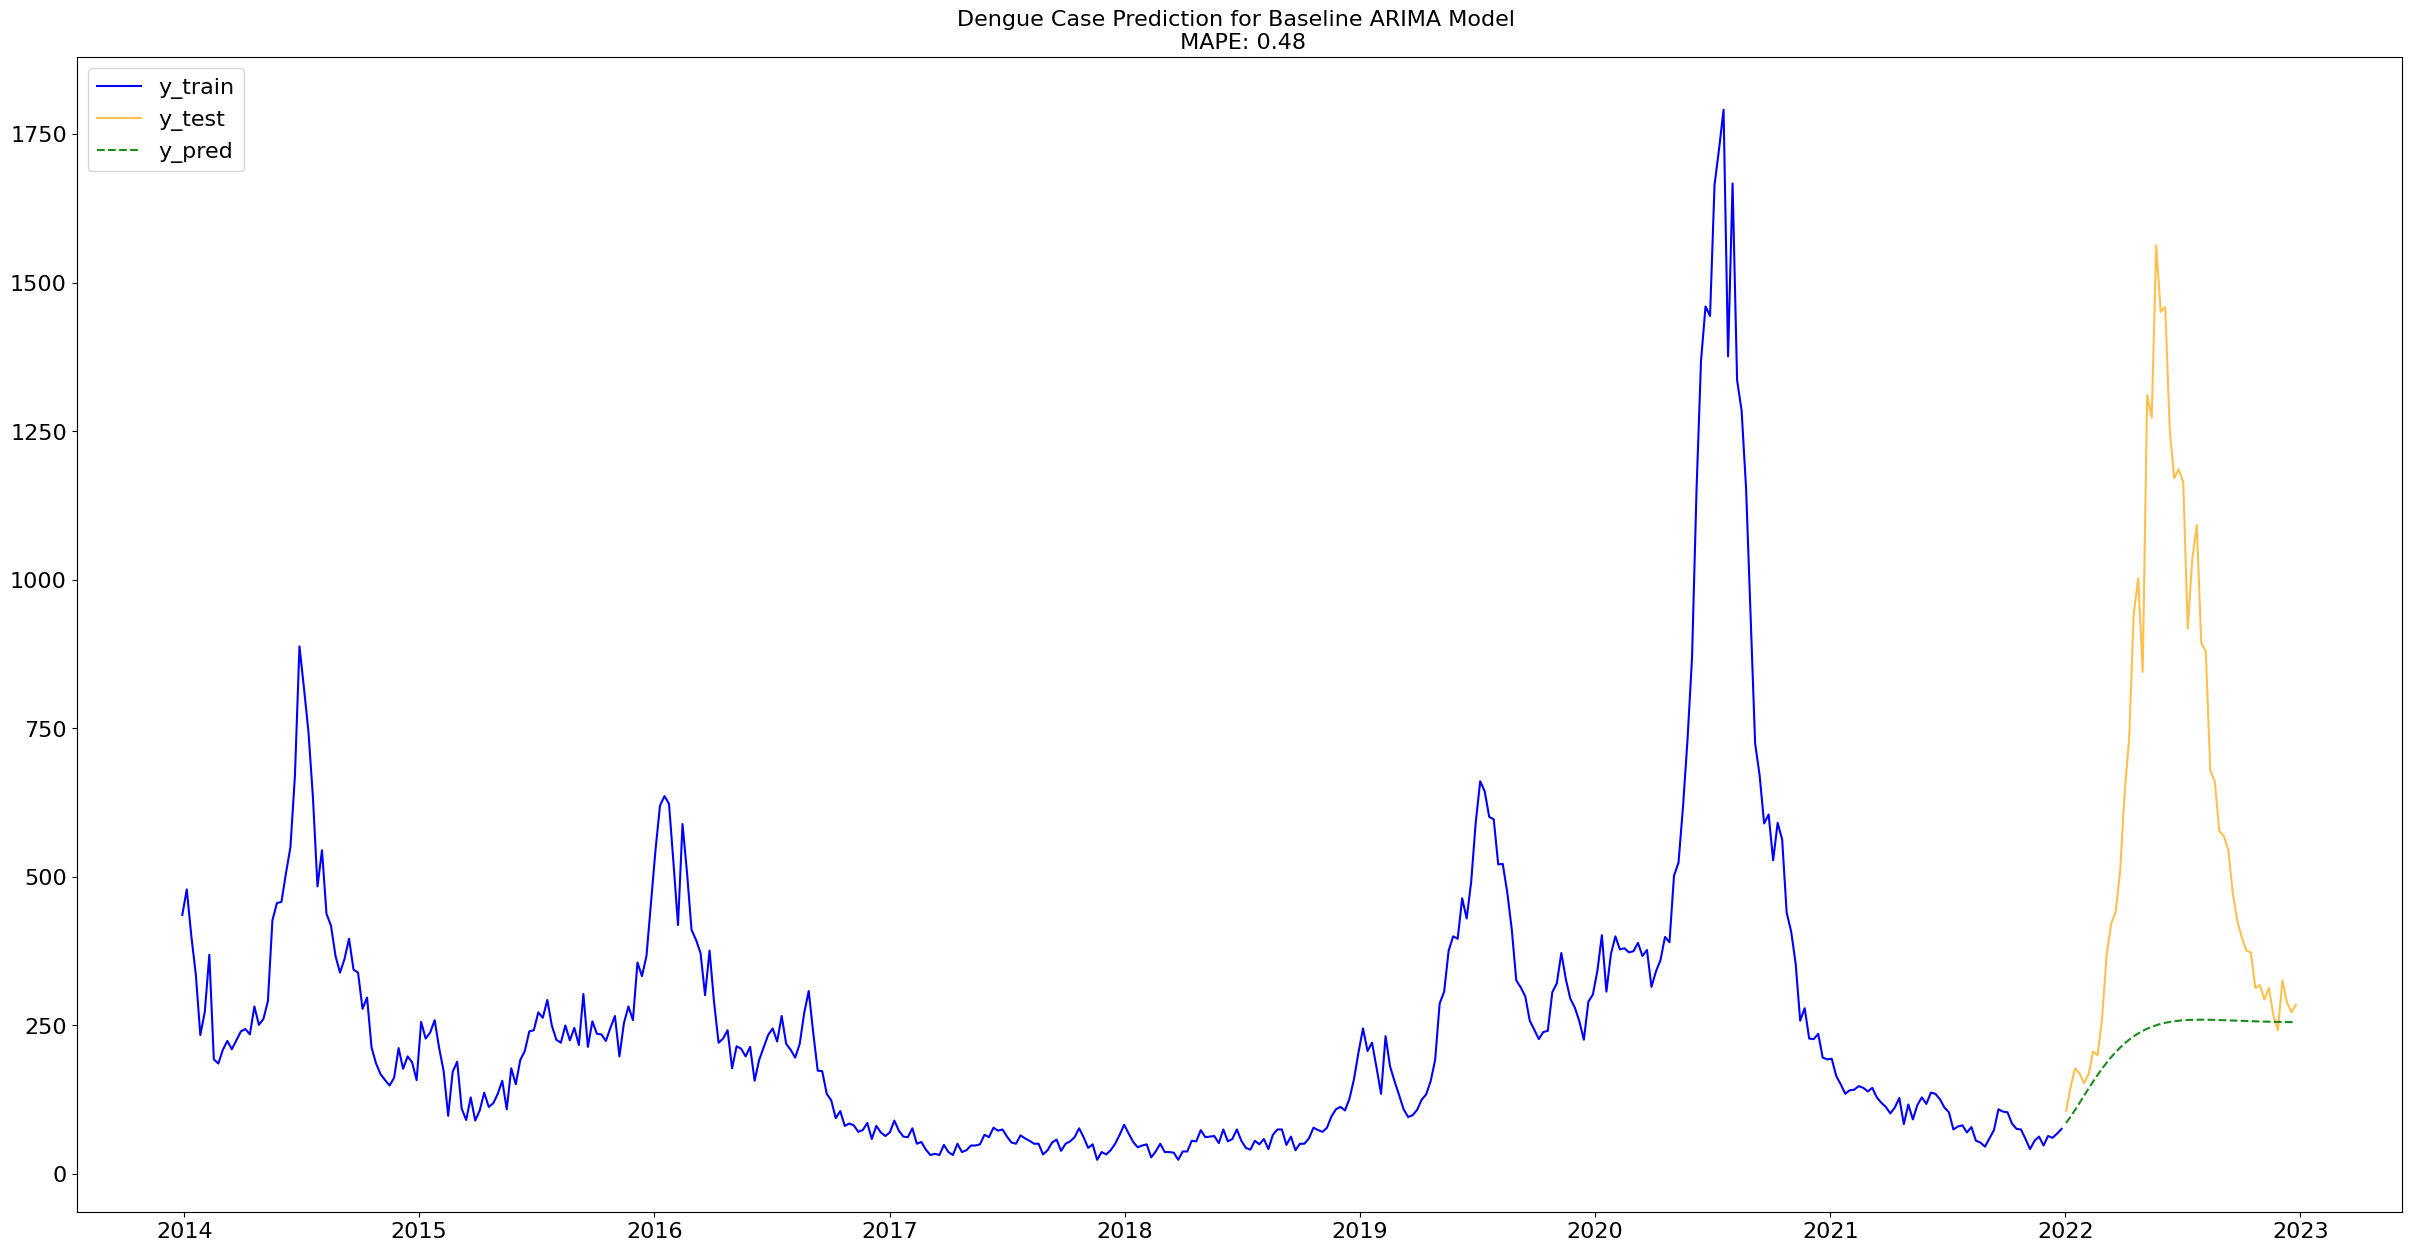

In [96]:
plot_forecast(y_train, y_test, arima_model, 'Baseline ARIMA Model')

**Comments**

* The baseline model [ARIMA(2,0,2)] has a MAPE of 0.48 which implies a 48% error in prediction, hence making it an undesirable model.
* Let's try by shortening the test size to 6 months (26 weeks) and see if the model improves.

### 2.2 ARIMA Model 1

#### (prediction period: 6 months / 26 weeks)

In [97]:
y_train_1 = y[:'2022-06-26']
y_test_1 = y['2022-07-03':]

In [98]:
arima_model.fit(y_train_1)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=4968.946, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=4970.862, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=4970.897, Time=0.03 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=4967.240, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=4954.308, Time=0.07 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=4912.421, Time=0.05 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=4918.844, Time=0.02 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=4914.405, Time=0.08 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=4914.394, Time=0.08 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=4916.377, Time=0.09 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=4914.223, Time=0.05 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=4915.978, Time=0.18 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=4910.470, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=4952.388, Time=0.04 sec
 ARIMA(2,1,0)(0,0,0)[0]          

AutoARIMA(max_p=13, max_q=13, n_fits=50, random_state=20, start_p=0, start_q=0,
          trace=True)

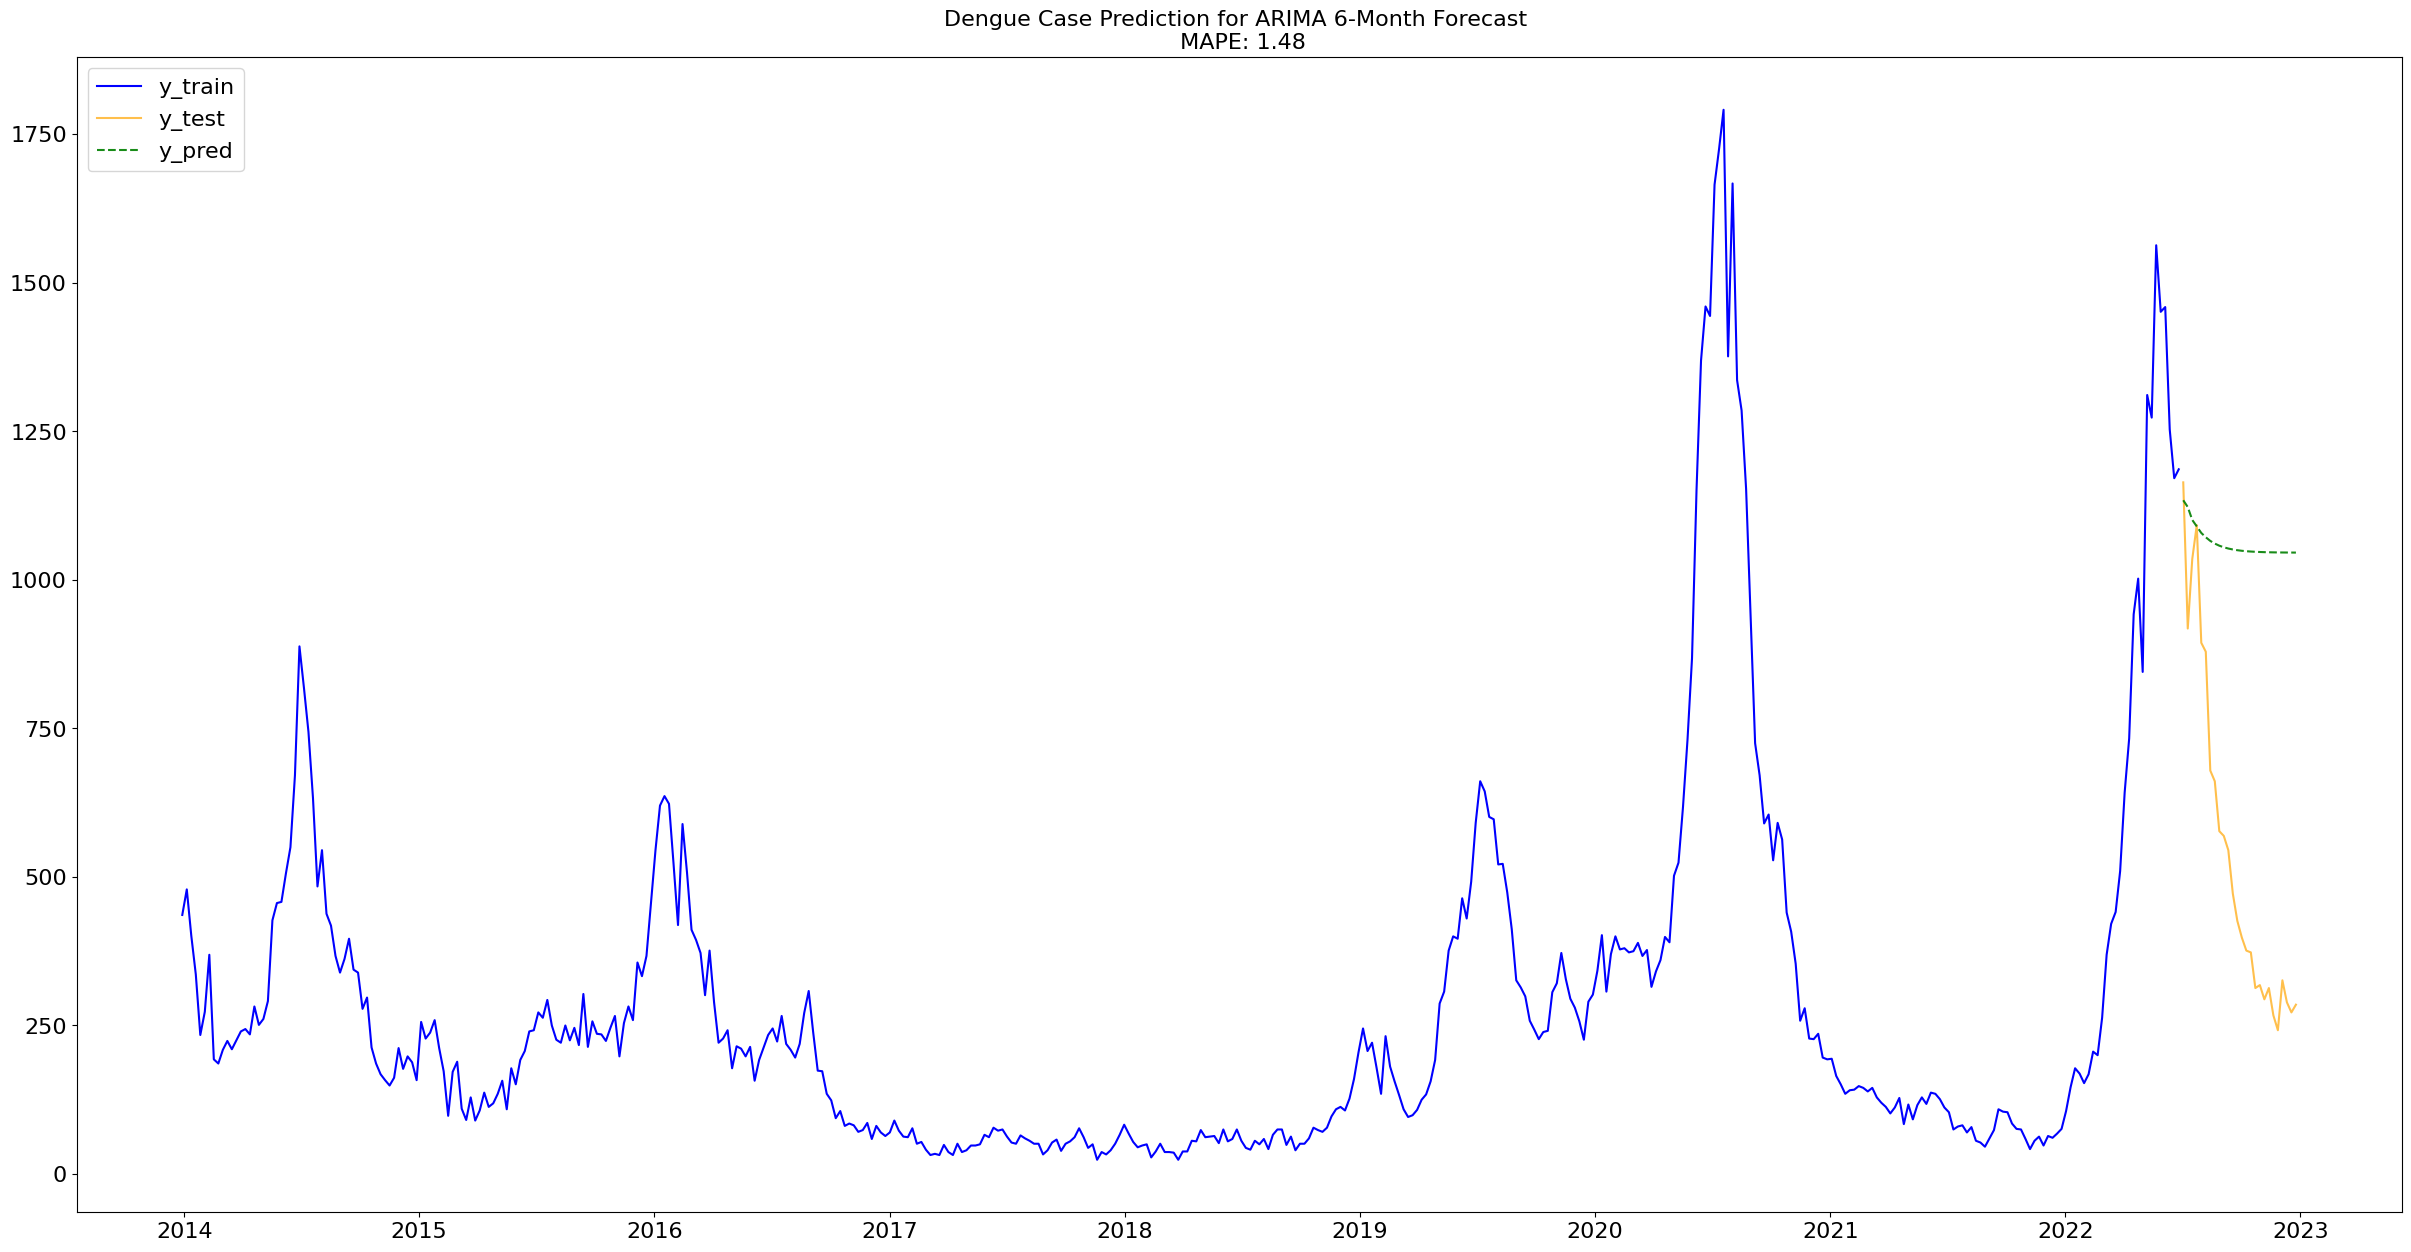

In [99]:
plot_forecast(y_train_1, y_test_1, arima_model, 'ARIMA 6-Month Forecast')

**Model Summary**

|                          | Baseline ARIMA              | ARIMA 1                                      |
| ------------------------ | --------------------------- | -------------------------------------------- |
| Model                    | ARIMA                       | ARIMA                                        |
| Best Parameters Returned | p,d,q = (2,0,2)             | p,d,q = (2,1,1)                              |
| Train Size               | weekly cases from 2014-2021 | weekly cases from 2014 to first half of 2022 |
| Test Size                | 2022                        | second half of 2022                          |
| MAPE                     | 0.48                        | 1.48                                         |

**Comments**

* With test size (prediction period) shortened to 6 months, the MAPE has worsened significantly to 1.48. This could be due to the erratic trend of dengue cases across the years, which makes it difficult for the model to learn and generate prediction more accurately for a relatively short duration.
* Let's try to see if the model improves by removing the 'outlier' covid period (year 2020) from the training data.

### 2.3 ARIMA Model 2

#### (outlier covid period omitted, prediction period: 6 months / 26 weeks)

Assuming that the patterns observed in the data from 2014 to 2019 will continue into the future, we will remove the 'outlier' covid period (year 2020) from the training data.

In [100]:
# Remove year 2020 from the dataset
yr2014_2019 = weekly_dengue.loc['2013-12-29':'2019-12-22']
yr2021_2022 = weekly_dengue.loc['2021-01-03':'2022-12-25']

In [101]:
# combine the two datasets
without_2020 = pd.concat([yr2014_2019, yr2021_2022])

without_2020.sort_index(inplace=True)

In [102]:
print (f'Shape(row,col): {without_2020.shape}')
print (f'Range of dates: {without_2020.index.min()} to {without_2020.index.max()}')
without_2020.head()

Shape(row,col): (417, 1)
Range of dates: 2013-12-29 00:00:00 to 2022-12-25 00:00:00


,number
date,
2013-12-29,436.000
2014-01-05,479.000
2014-01-12,401.000
2014-01-19,336.000
2014-01-26,234.000


In [103]:
y_ = without_2020['number']

In [104]:
y_train_no20 = y_[:'2022-06-26']
y_test_no20 = y_['2022-07-03':]

In [105]:
arima_model.fit(y_train_no20)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=5380.285, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=4230.196, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=4980.089, Time=0.04 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=5633.963, Time=0.00 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=inf, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=4231.757, Time=0.05 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=4227.567, Time=0.07 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=4204.633, Time=0.09 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=4209.907, Time=0.04 sec
 ARIMA(4,0,1)(0,0,0)[0] intercept   : AIC=4205.946, Time=0.15 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=4205.914, Time=0.11 sec
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=4212.018, Time=0.13 sec
 ARIMA(4,0,0)(0,0,0)[0] intercept   : AIC=4208.934, Time=0.09 sec
 ARIMA(4,0,2)(0,0,0)[0] intercept   : AIC=4208.330, Time=0.17 sec
 ARIMA(3,0,1)(0,0,0)[0]             : 

AutoARIMA(max_p=13, max_q=13, n_fits=50, random_state=20, start_p=0, start_q=0,
          trace=True)

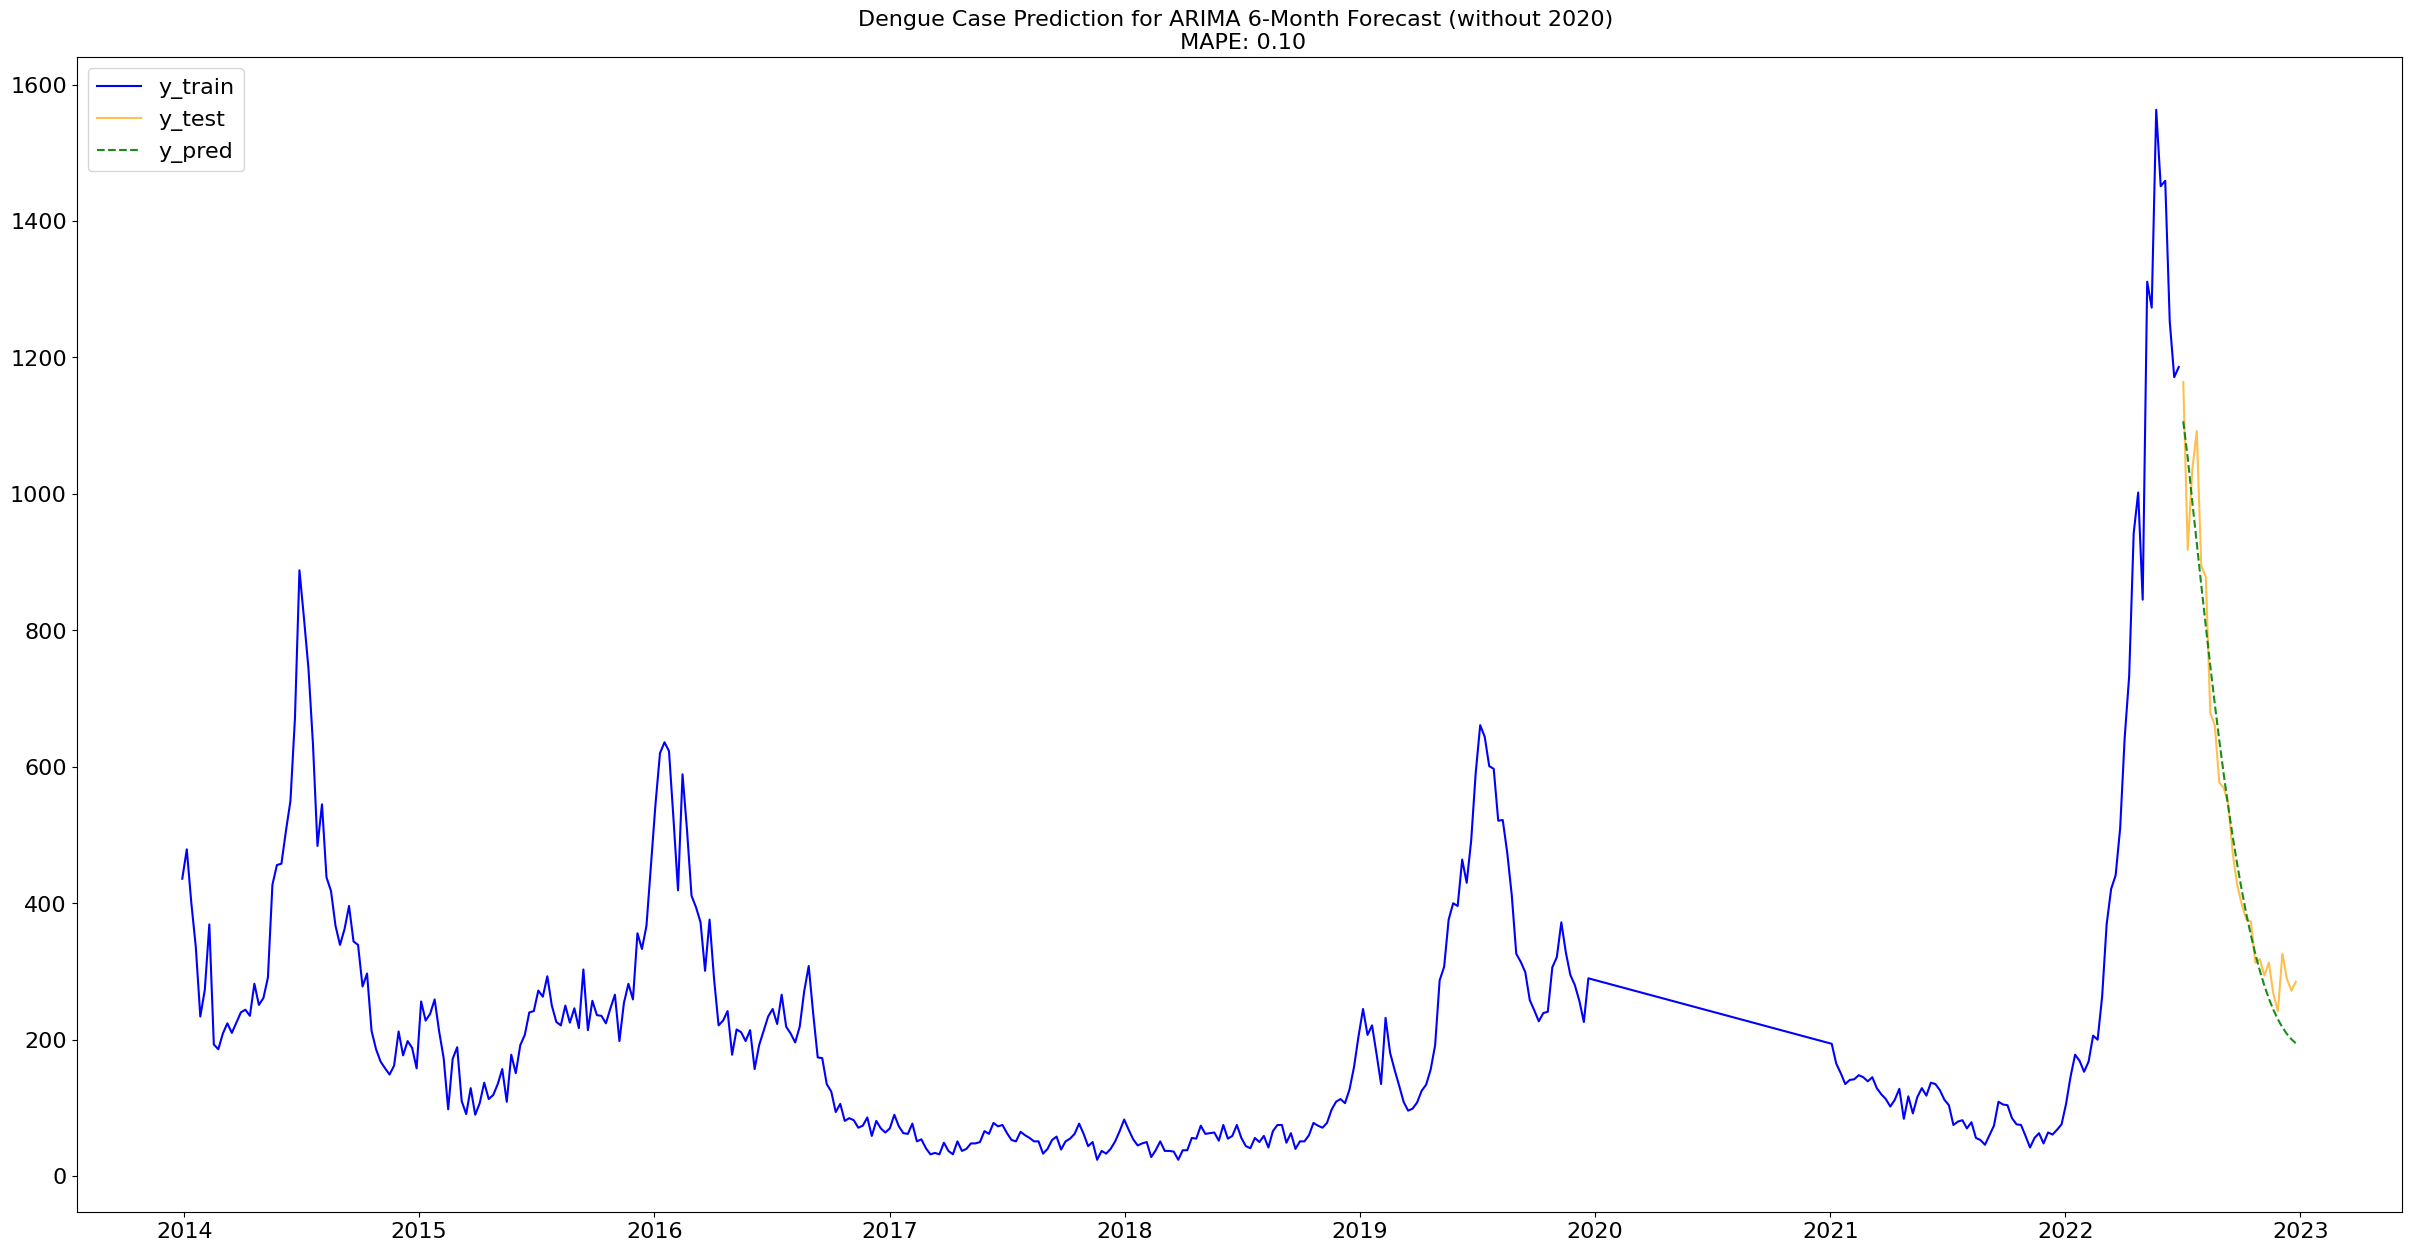

In [106]:
plot_forecast(y_train_no20, y_test_no20, arima_model, 'ARIMA 6-Month Forecast (without 2020)')

**Model Summary**

|                          | Baseline ARIMA              | ARIMA 1                                      | ARIMA 2                                                             |
| ------------------------ | --------------------------- | -------------------------------------------- | ------------------------------------------------------------------- |
| Model                    | ARIMA                       | ARIMA                                        | ARIMA                                                               |
| Best Parameters Returned | p,d,q = (2,0,2)             | p,d,q = (2,1,1)                              | p,d,q = (3,0,1)                                                     |
| Train Size               | weekly cases from 2014-2021 | weekly cases from 2014 to first half of 2022 | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) |
| Test Size                | 2022                        | second half of 2022                          | second half of 2022                                                 |
| MAPE                     | 0.48                        | 1.48                                         | 0.10                                                                |

**Comments**

* With prediction period reduced to 6 months, the model has improved significantly with a MAPE of 0.10, which has met our target of 0.10 or less. 
* Let's see if the error will reduce further if we reduce the prediction period to 3 months.

### 2.4. ARIMA Model 3

#### (outlier covid period omitted, prediction period: 3 months / 13 weeks)

In [107]:
y_train_3m = y_[:'2022-09-25']
y_test_3m = y_['2022-10-02':]

In [108]:
arima_model.fit(y_train_3m)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=4400.251, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=4401.239, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=4401.547, Time=0.03 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=4398.251, Time=0.00 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=4396.689, Time=0.06 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=4378.087, Time=0.04 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=4384.376, Time=0.01 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=4380.079, Time=0.07 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=4380.077, Time=0.07 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=4378.999, Time=0.07 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=4381.177, Time=0.04 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=4382.087, Time=0.08 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=4376.100, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=4394.698, Time=0.03 sec
 ARIMA(2,1,0)(0,0,0)[0]          

AutoARIMA(max_p=13, max_q=13, n_fits=50, random_state=20, start_p=0, start_q=0,
          trace=True)

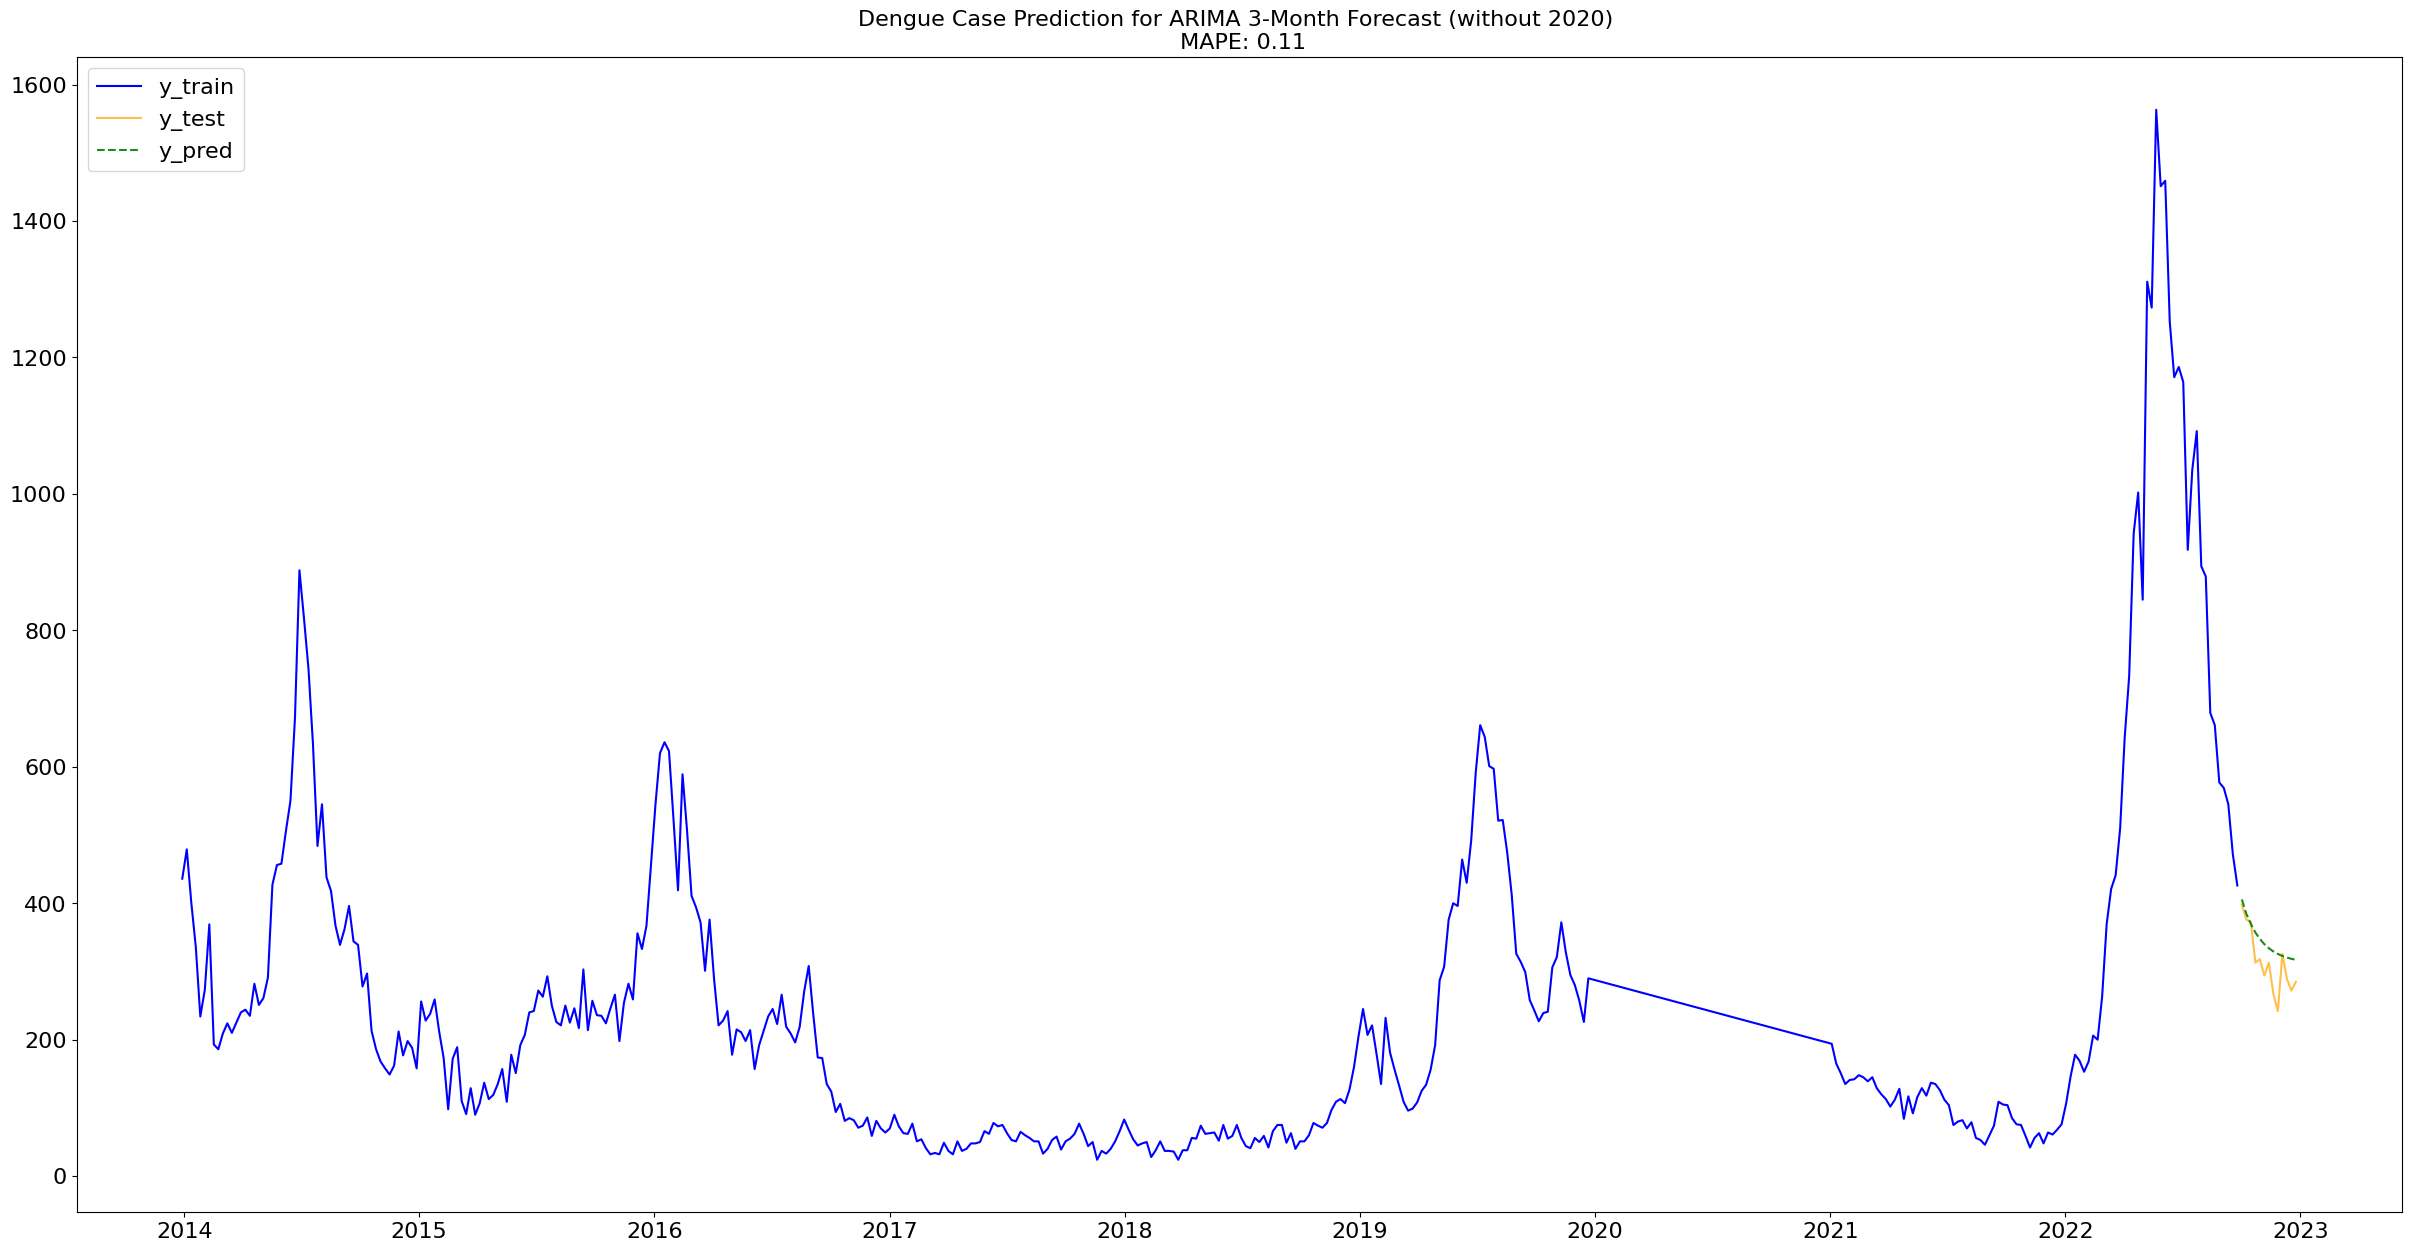

In [109]:
plot_forecast(y_train_3m, y_test_3m, arima_model, 'ARIMA 3-Month Forecast (without 2020)')

|                          | Baseline ARIMA              | ARIMA 1                                      | ARIMA 2 (Best)                                                      | ARIMA 3                                                     |
| ------------------------ | --------------------------- | -------------------------------------------- | ------------------------------------------------------------------- | ----------------------------------------------------------- |
| Model                    | ARIMA                       | ARIMA                                        | ARIMA                                                               | ARIMA                                                       |
| Best Parameters Returned | p,d,q = (2,0,2)             | p,d,q = (2,1,1)                              | p,d,q = (3,0,1)                                                     | p,d,q = (2,1,1)                                             |
| Train Size               | weekly cases from 2014-2021 | weekly cases from 2014 to first half of 2022 | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) | weekly cases from 2014 to Q3 of 2022 (outlier 2020 omitted) |
| Test Size                | 2022                        | second half of 2022                          | second half of 2022                                                 | last quarter of 2022                                        |
| MAPE                     | 0.48                        | 1.48                                         | 0.10                                                                | 0.11                                                        |

**Comments**

* With prediction period reduced to 3 months, the MAPE has worsened slightly to 0.11 instead.
* Normally, there tend to be higher uncertainty in longer term forecast. In this scenario, it could be possible that the longer 6-month prediction may be based on more stable and smoother trends in the data, resulting in more accurate forecast with lower MAPE values compared to shorter 3-month prediction that might be influenced by short-term fluctuations or noise.
* We will stick to a 6-month prediction period for subsequent modelling.

### 2.5. SARIMA Model

#### (outlier covid period omitted, prediction period: 6 months / 26 weeks)

In [110]:
# If there is a certain pattern for one 13-week interval as indicated by the PCF plot, try to see if there is a seasonality in the data that can be captured
sarima_model = pm.AutoARIMA(start_p=0, max_p=13, 
                           d=None,
                           start_q=0, max_q=13,
                           
                           start_P=0, max_P=13,
                           D=None,
                           start_Q=0, max_Q=13,
                           m=13, # data used is weekly
                           seasonal=True,
                           
                           trace=True, 
                           random_state=20,
                           n_fits=50)

In [111]:
sarima_model.fit(y_train_no20)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[13] intercept   : AIC=5380.285, Time=0.01 sec
 ARIMA(1,0,0)(1,0,0)[13] intercept   : AIC=4231.735, Time=0.48 sec
 ARIMA(0,0,1)(0,0,1)[13] intercept   : AIC=4961.119, Time=0.67 sec
 ARIMA(0,0,0)(0,0,0)[13]             : AIC=5633.963, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[13] intercept   : AIC=4230.196, Time=0.03 sec
 ARIMA(1,0,0)(0,0,1)[13] intercept   : AIC=4231.749, Time=0.55 sec
 ARIMA(1,0,0)(1,0,1)[13] intercept   : AIC=4232.321, Time=0.76 sec
 ARIMA(2,0,0)(0,0,0)[13] intercept   : AIC=inf, Time=0.10 sec
 ARIMA(1,0,1)(0,0,0)[13] intercept   : AIC=4231.757, Time=0.09 sec
 ARIMA(0,0,1)(0,0,0)[13] intercept   : AIC=4980.089, Time=0.06 sec
 ARIMA(2,0,1)(0,0,0)[13] intercept   : AIC=4227.567, Time=0.07 sec
 ARIMA(2,0,1)(1,0,0)[13] intercept   : AIC=4229.212, Time=0.57 sec
 ARIMA(2,0,1)(0,0,1)[13] intercept   : AIC=4229.228, Time=0.86 sec
 ARIMA(2,0,1)(1,0,1)[13] intercept   : AIC=4230.131, Time=1.06 sec
 ARIMA(3,0,1)(0,0,0)[13]

AutoARIMA(m=13, max_P=13, max_Q=13, max_p=13, max_q=13, n_fits=50,
          random_state=20, start_P=0, start_Q=0, start_p=0, start_q=0,
          trace=True)

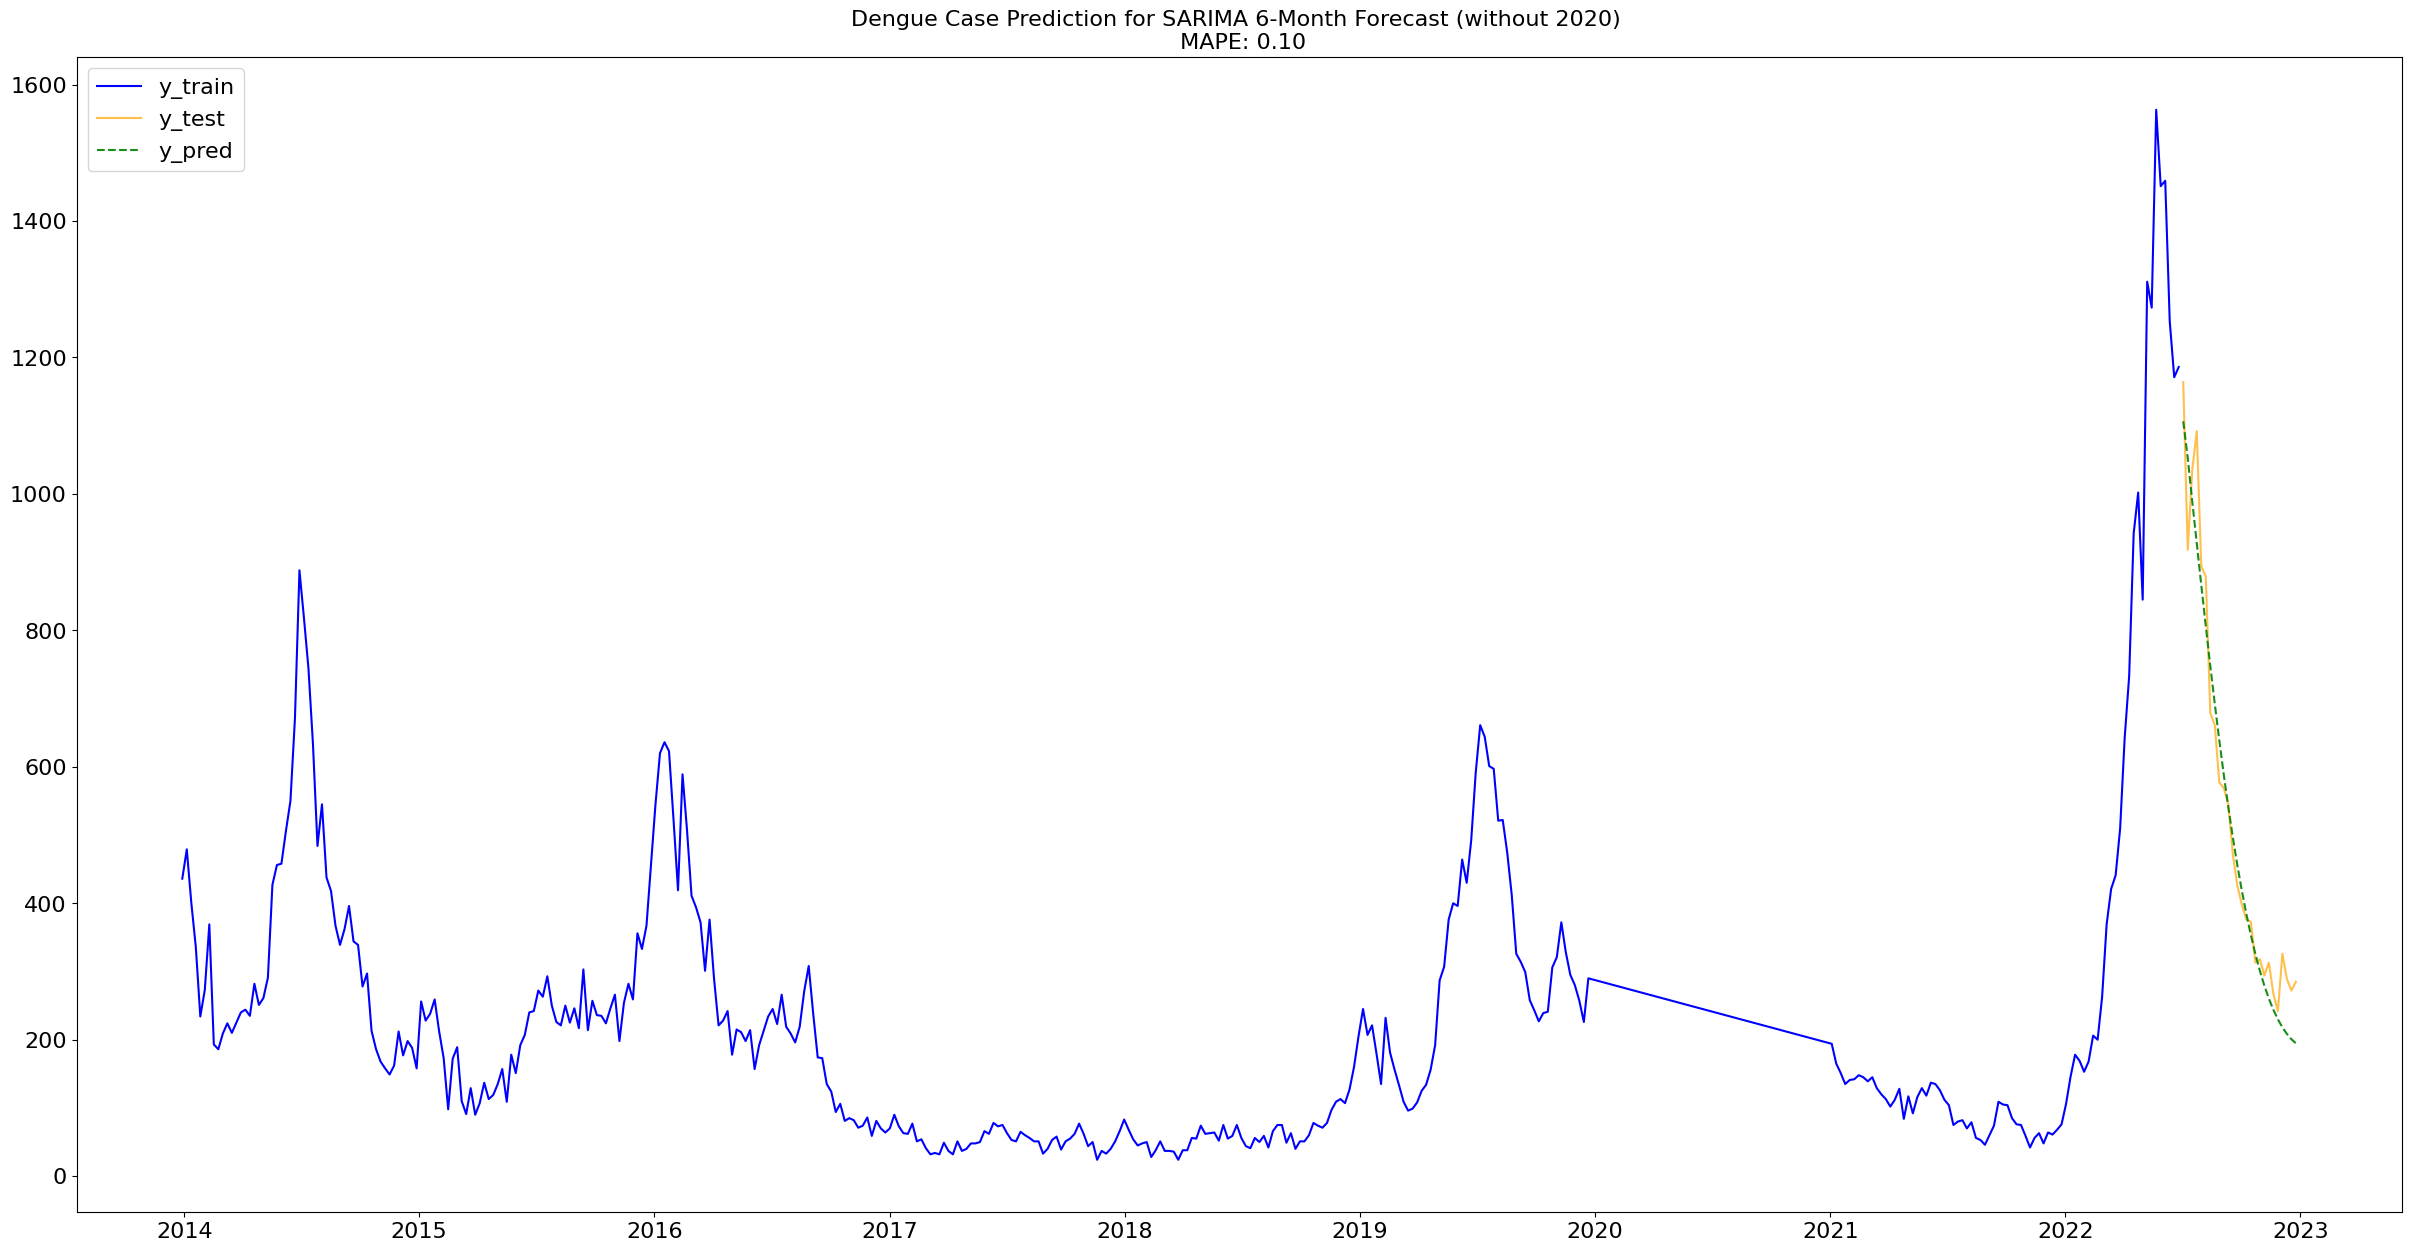

In [112]:
plot_forecast(y_train_no20, y_test_no20, sarima_model, 'SARIMA 6-Month Forecast (without 2020)')

|                          | Baseline ARIMA              | ARIMA 1                                      | ARIMA 2 (Best)                                                      | ARIMA 3                                                     | SARIMA                                                              |
| ------------------------ | --------------------------- | -------------------------------------------- | ------------------------------------------------------------------- | ----------------------------------------------------------- | ------------------------------------------------------------------- |
| Model                    | ARIMA                       | ARIMA                                        | ARIMA                                                               | ARIMA                                                       | SARIMA                                                              |
| Best Parameters Returned | p,d,q = (2,0,2)             | p,d,q = (2,1,1)                              | p,d,q = (3,0,1)                                                     | p,d,q = (2,1,1)                                             | p,d,q = (3,0,1)<br>P,D,Q = (0,0,0)                                  |
| Train Size               | weekly cases from 2014-2021 | weekly cases from 2014 to first half of 2022 | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) | weekly cases from 2014 to Q3 of 2022 (outlier 2020 omitted) | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) |
| Test Size                | 2022                        | second half of 2022                          | second half of 2022                                                 | last quarter of 2022                                        | second half of 2022                                                 |
| MAPE                     | 0.48                        | 1.48                                         | 0.10                                                                | 0.11                                                        | 0.10                                                                |

**Comments**

* The SARIMA model has a MAPE of 0.10, which sees no improvement from the ARIMA Version 2 model, hence there is no need to consider seasonality in subsequent modelling.

### 2.6. ARIMAX Model

#### (outlier covid period omitted, google search interest variable included, prediction period: 6 months / 26 weeks)

In [113]:
# Remove year 2020 from the dataset
yr14_19 = dengue_google.loc[:'2019-12-31']
yr21_22 = dengue_google.loc['2021-01-31':]

In [114]:
# combine the two datasets
dengue_google_2 = pd.concat([yr14_19, yr21_22])
dengue_google.sort_index(inplace=True)

In [115]:
dengue_google_2.head()

,dengue_cases,search_interest,prev_mth_search
date,,,
2014-02-28,1021.000,31,34.000
2014-03-31,1108.000,26,31.000
2014-04-30,1012.000,27,26.000
2014-05-31,1435.000,26,27.000
2014-06-30,3073.000,36,26.000


In [116]:
X = dengue_google_2['prev_mth_search']

X_train_s2 = X[:'2022-06-30']
X_test_s2 = X['2022-07-31':]

In [117]:
y = dengue_google_2['dengue_cases']

y_train_s2 = y[:'2022-06-30']
y_test_s2 = y['2022-07-31':]

In [118]:
# Reshape the data to 2D array

X_train_s2 = X_train_s2.values.reshape(-1,1)
X_test_s2 = X_test_s2.values.reshape(-1,1)

In [119]:
ss = StandardScaler()

X_train_s2 = ss.fit_transform(X_train_s2)
X_test_s2 = ss.transform(X_test_s2)

In [120]:
arima_model.fit(y_train_s2, X_train_s2)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=1445.092, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=1382.128, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=1399.983, Time=0.02 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=1525.649, Time=0.01 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=1376.886, Time=0.04 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=1380.065, Time=0.05 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=1380.952, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=1378.521, Time=0.05 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=1378.811, Time=0.06 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=1382.286, Time=0.03 sec

Best model:  ARIMA(2,0,0)(0,0,0)[0] intercept
Total fit time: 0.342 seconds


AutoARIMA(max_p=13, max_q=13, n_fits=50, random_state=20, start_p=0, start_q=0,
          trace=True)

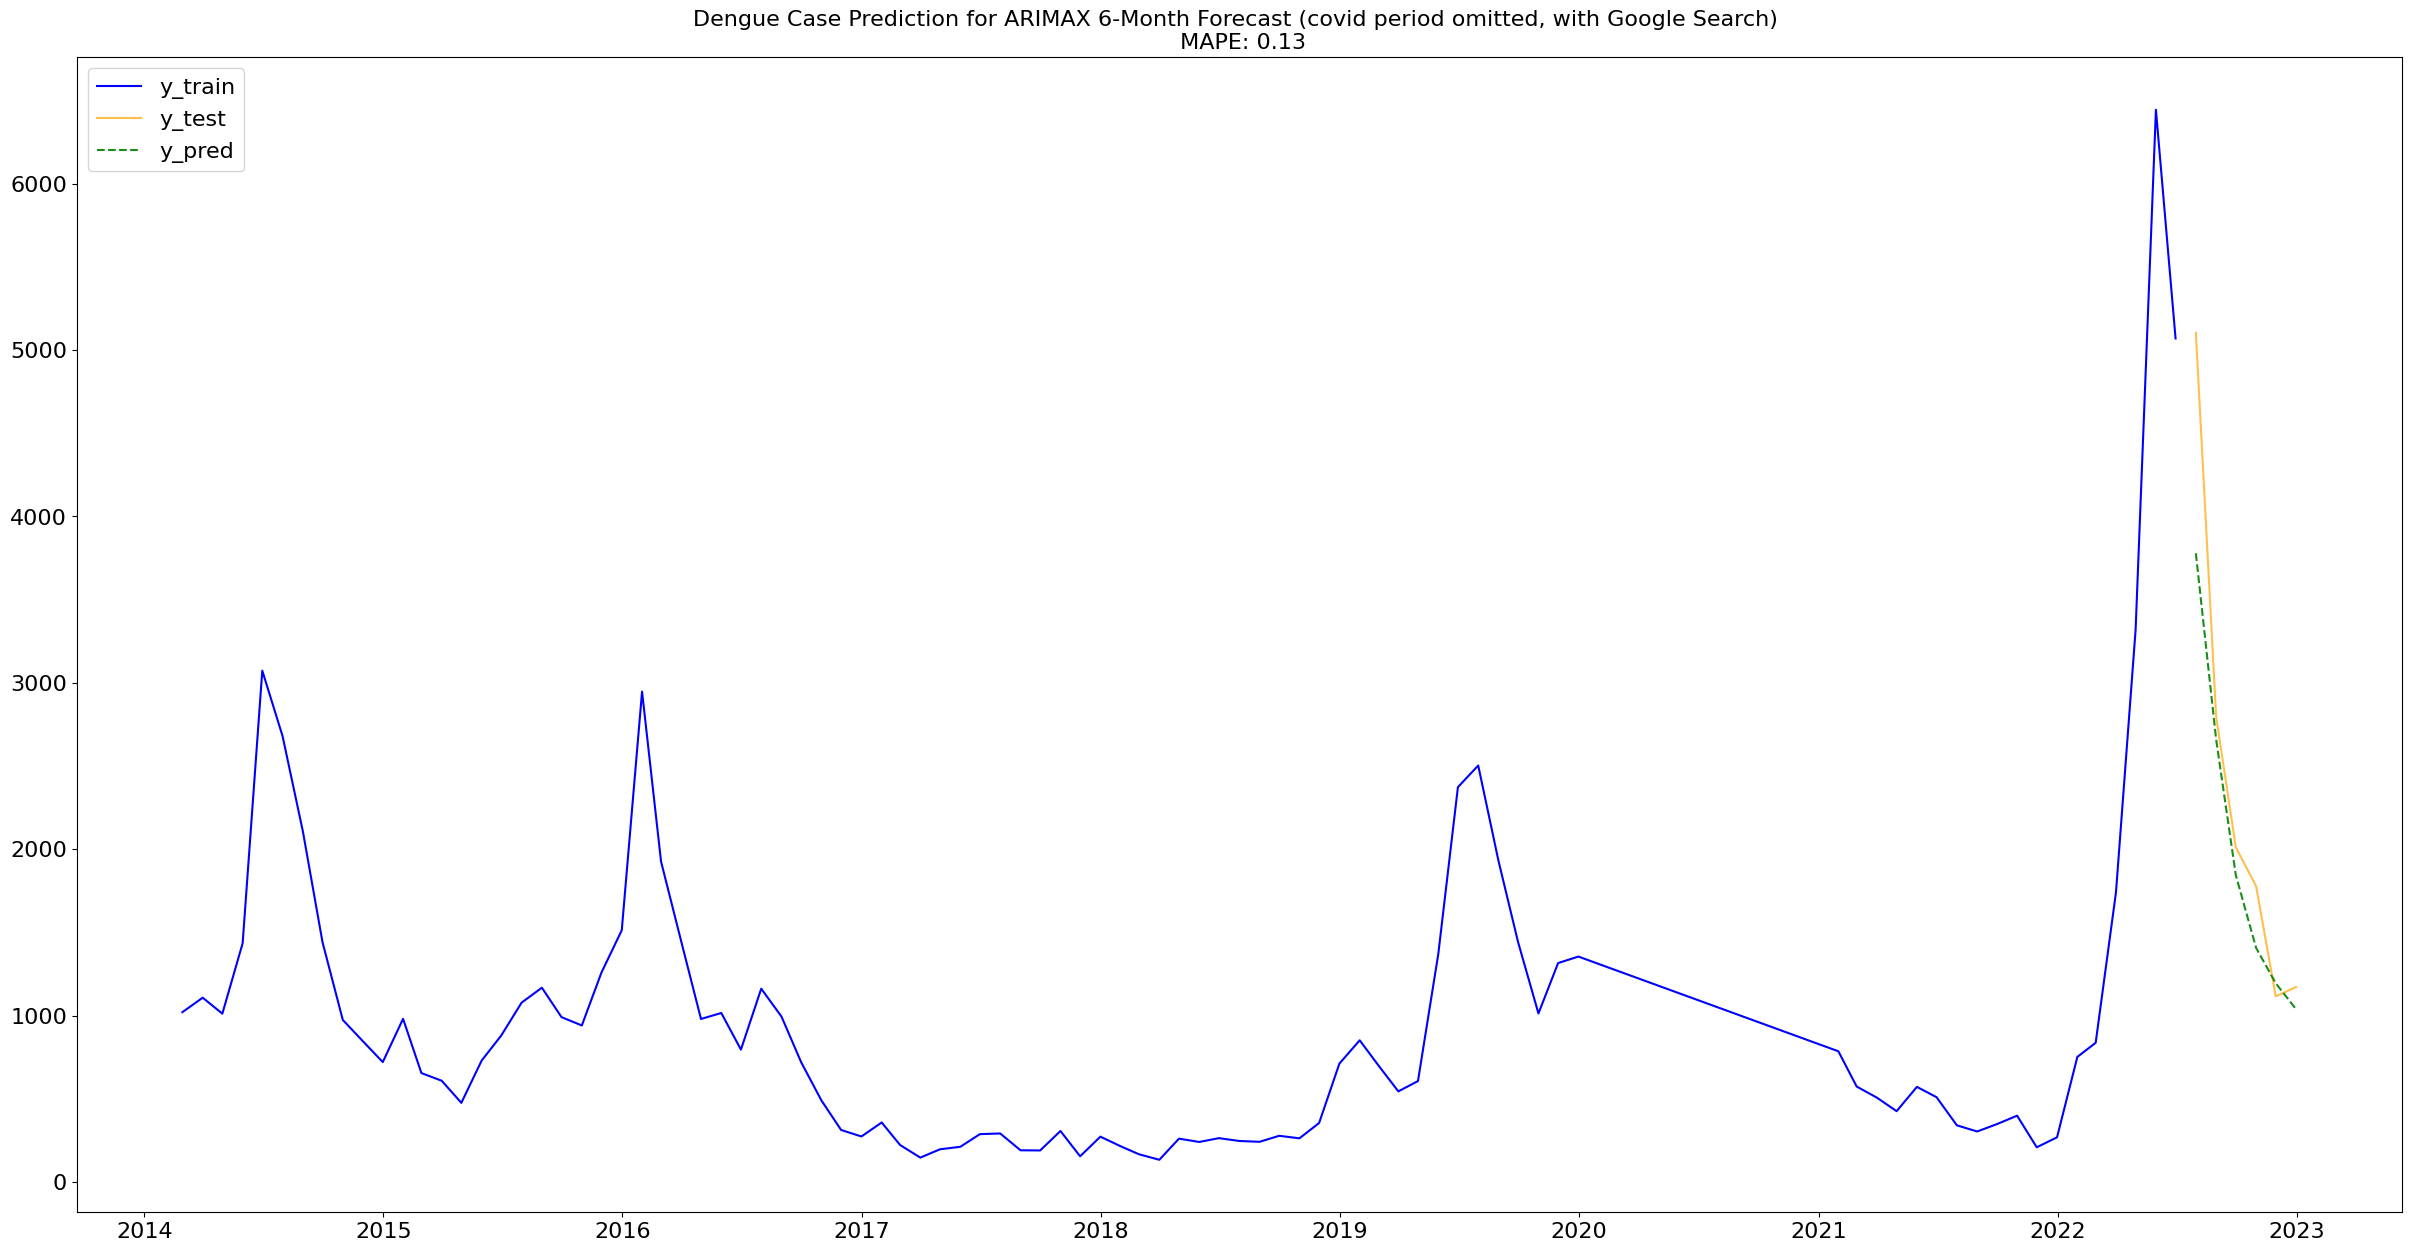

In [121]:
plot_forecast(y_train_s2, y_test_s2, arima_model, 'ARIMAX 6-Month Forecast (covid period omitted, with Google Search)', X_test_s2)

|                          | Baseline ARIMA              | ARIMA 1                                      | ARIMA 2 (Best)                                                      | ARIMA 3                                                     | SARIMA                                                              | ARIMAX                                                                                                       |
| ------------------------ | --------------------------- | -------------------------------------------- | ------------------------------------------------------------------- | ----------------------------------------------------------- | ------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------ |
| Model                    | ARIMA                       | ARIMA                                        | ARIMA                                                               | ARIMA                                                       | SARIMA                                                              | ARIMAX                                                                                                       |
| Best Parameters Returned | p,d,q = (2,0,2)             | p,d,q = (2,1,1)                              | p,d,q = (3,0,1)                                                     | p,d,q = (2,1,1)                                             | p,d,q = (3,0,1)<br>P,D,Q = (0,0,0)                                  | p,d,q = (2,0,0)                                                                                              |
| Train Size               | weekly cases from 2014-2021 | weekly cases from 2014 to first half of 2022 | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) | weekly cases from 2014 to Q3 of 2022 (outlier 2020 omitted) | weekly cases from 2014 to first half of 2022 (outlier 2020 omitted) | monthly cases from 2014 to first half of 2022 (outlier 2020 omitted) and prev month's google search interest |
| Test Size                | 2022                        | second half of 2022                          | second half of 2022                                                 | last quarter of 2022                                        | second half of 2022                                                 | second half of 2022                                                                                          |
| MAPE                     | 0.48                        | 1.48                                         | 0.10                                                                | 0.11                                                        | 0.10                                                                | 0.13                                                                                                         |

**Comments**

* With an exogenous variable of previous month's google search interest for 'dengue' considered, the MAPE of 0.13 is higher than ARIMA model Version 2's 0.10. Hence, it confirmed our earlier inference on google search interest not being a good predictor of dengue cases.
  
* Also, with previous month's data of google search interest considered, it implies that the longest forecast horizon that we can have is the next month's dengue cases, which is not ideal for our use case as it takes time for NEA to plan and deploy the right amount resources to clamp down on dengue cases.

## 3. Model Evaluation & Prediction

* The model to be used for the cost benefit analysis is the **ARIMA 2 model** as it has the lowest MAPE score of 0.10, which implies the lowest error rate of 10% in prediction of dengue cases.
  
* A prediction period of 6 months/26 weeks is also an appropriate time frame for NEA to plan and allocate resources for the prevention and control of dengue cases.

* The selected model will be used to predict the number of dengue cases in 2H 2022 and see how that has changed compared to the previous time period in 1H 2022.

In [125]:
# Generate number of predicted cases for 2H 2022 using ARIMA 2 model:

def get_predictions(train, test, model):
    model.fit(train)  # Fit the ARIMA model with the training data
    pred = model.predict(n_periods=len(test))  # Generate predictions
    return pred

predictions = get_predictions(y_train_no20, y_test_no20, arima_model)

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=5380.285, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=4230.196, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=4980.089, Time=0.04 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=5633.963, Time=0.00 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=inf, Time=0.05 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=4231.757, Time=0.05 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=4227.567, Time=0.07 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=4204.633, Time=0.09 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=4209.907, Time=0.04 sec
 ARIMA(4,0,1)(0,0,0)[0] intercept   : AIC=4205.946, Time=0.15 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=4205.914, Time=0.11 sec
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=4212.018, Time=0.13 sec
 ARIMA(4,0,0)(0,0,0)[0] intercept   : AIC=4208.934, Time=0.09 sec
 ARIMA(4,0,2)(0,0,0)[0] intercept   : AIC=4208.330, Time=0.18 sec
 ARIMA(3,0,1)(0,0,0)[0]             : 

Assuming that we are at the end of the 1H 2022, and that we are using the selected model to predict for the next half of 2022 to see if there is a need to increase/decrease resources for the prevention and control of dengue cases:

In [135]:
# Print the predicted cases for 2H 2022
print(f'Predicted cases for 2H 2022: {predictions.sum():.0f}')

Predicted cases for 2H 2022: 13526


In [131]:
# Actual number of dengue cases for 1H 2022

weekly_dengue.loc['2022-01-02':'2022-06-26'].sum()

number   18161.000
dtype: float64

In [133]:
# % change in predicted cases for 2H 2022 vs actual cases for 1H 2022

print(f'Predicted % change in number of dengue cases for 2H 2022:{((13526-18161)/18161)*100:.2f}% ')

Predicted % change in number of dengue cases for 2H 2022:-25.52% 


**Comments**

* The number of dengue cases predicted by the ARIMA 2 model for 2H 2022 is 13526, which represents a projected 25.52% decrease compared to 1H 2022.
  
* This predicted number can deviate by ~10% based on the model's MAPE score of 0.10, which means it may be as high as 14879 or as low as 12174.
  
* Bearing these predictions in mind, NEA can then decide if there is a need to increase/decrease resources for the prevention and control of dengue cases.